# Week 11-12 · Dimensionality Reduction · Part 2: t-SNE (intuition)

## The idea
t-SNE (*t-distributed Stochastic Neighbour Embedding*, van der Maaten & Hinton, 2008) is a **non-linear** technique built for **visualising** high-dimensional data in 2D/3D.

**Intuition in 3 steps**
1. In the high-D space, for each point compute the probability that every other point is its *neighbour* (Gaussian kernel; nearby points get high probability).
2. Place the points randomly in 2D and compute the same neighbour probabilities there using a heavy-tailed **Student-t distribution**.
3. Move the 2D points by **gradient descent** to minimise the KL divergence between the two sets of probabilities, so that points that were neighbours stay neighbours.

The heavy tails of the t-distribution let clusters spread apart and avoid the "crowding problem".

**Key hyperparameter: `perplexity`** ≈ effective number of neighbours considered (typically 5-50).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
np.random.seed(42)

In [2]:
digits = pd.read_csv("../data/digits.csv")
X = digits.drop(columns="target").values
y = digits["target"].values
print(X.shape)

(1797, 64)


## 1. Basic t-SNE on Digits (64D -> 2D)

t-SNE took 8.2s


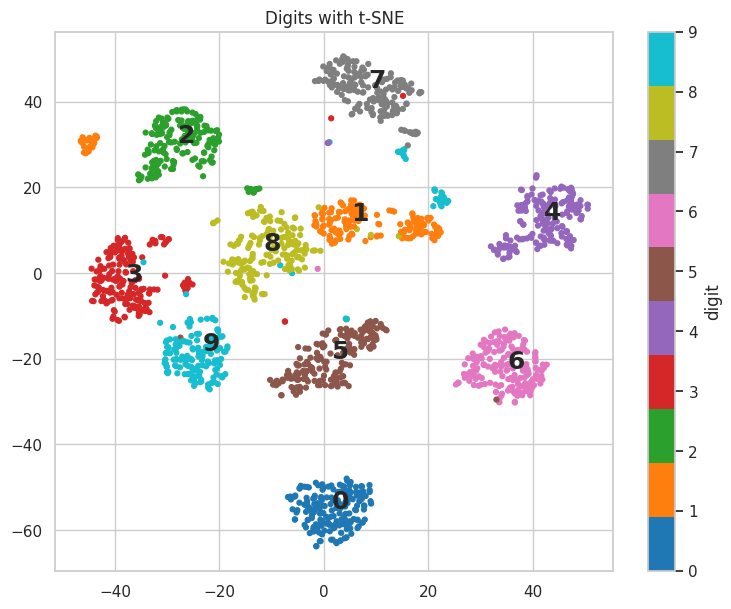

In [3]:
t0 = time.time()
Z_tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=42).fit_transform(X)
print(f"t-SNE took {time.time()-t0:.1f}s")

plt.figure(figsize=(9,7))
sc = plt.scatter(Z_tsne[:,0], Z_tsne[:,1], c=y, cmap="tab10", s=12)
plt.colorbar(sc, label="digit")
for d in range(10):
    cx, cy = np.median(Z_tsne[y==d], axis=0)
    plt.text(cx, cy, str(d), fontsize=18, weight="bold")
plt.title("Digits with t-SNE"); plt.show()

The ten digit classes form well-separated clusters, much cleaner than PCA's 2D plot. t-SNE keeps **local neighbourhoods** intact.

## 2. Effect of perplexity

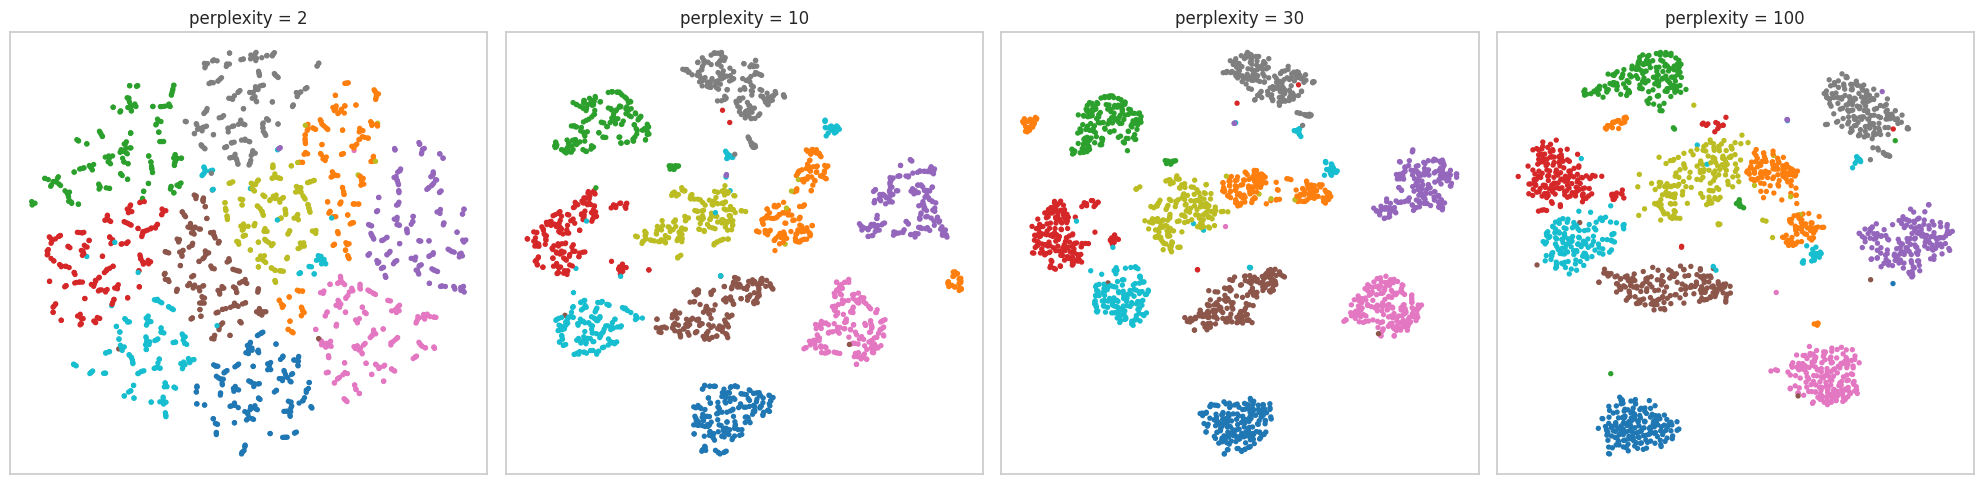

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(20,5))
for ax, p in zip(axes, [2, 10, 30, 100]):
    Z = TSNE(perplexity=p, init="pca", learning_rate="auto", random_state=42).fit_transform(X)
    ax.scatter(Z[:,0], Z[:,1], c=y, cmap="tab10", s=8)
    ax.set_title(f"perplexity = {p}"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

- **Low perplexity (2):** focuses on tiny neighbourhoods -> fragmented clusters.
- **Medium (10-50):** usually the sweet spot.
- **High (100):** more global view, clusters may merge.

## 3. Different random seeds -> different pictures
t-SNE is **stochastic**. Cluster *shapes* and *positions* can change; what should stay is *which points group together*.

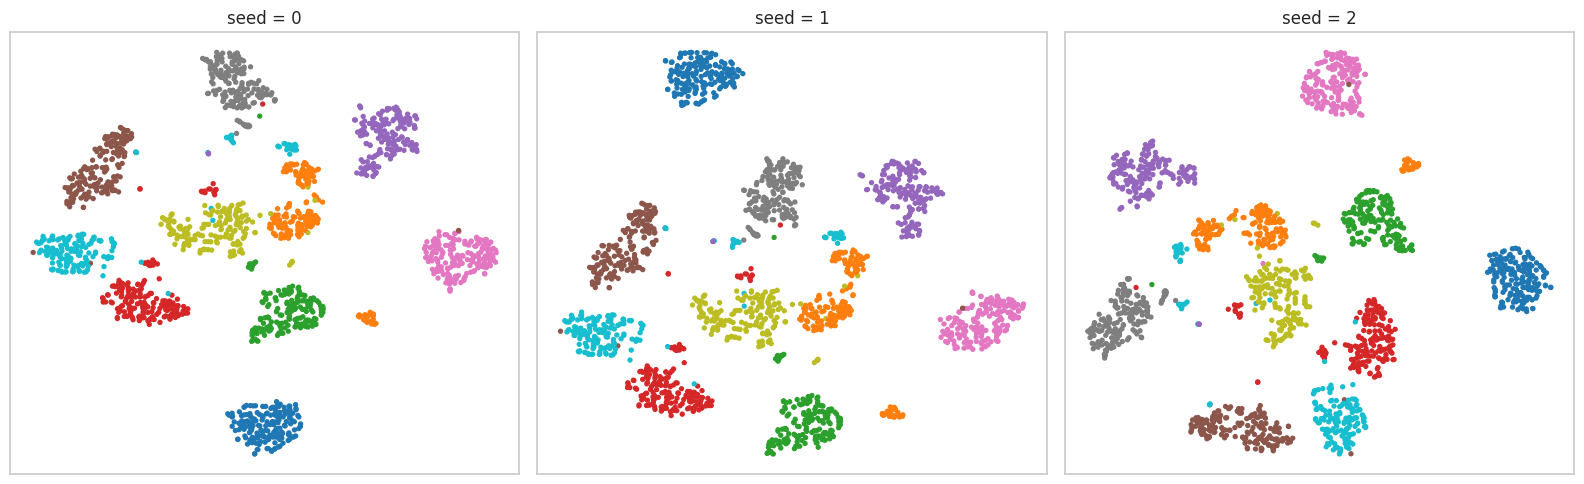

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16,5))
for ax, seed in zip(axes, [0, 1, 2]):
    Z = TSNE(perplexity=30, init="random", learning_rate="auto", random_state=seed).fit_transform(X)
    ax.scatter(Z[:,0], Z[:,1], c=y, cmap="tab10", s=8); ax.set_title(f"seed = {seed}")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 4. Best practice: PCA first, then t-SNE
For very high-dimensional data (hundreds+ features), first reduce to ~30-50 dims with PCA to remove noise and speed things up.

Direct: 8.7s | PCA(30)->t-SNE: 8.1s


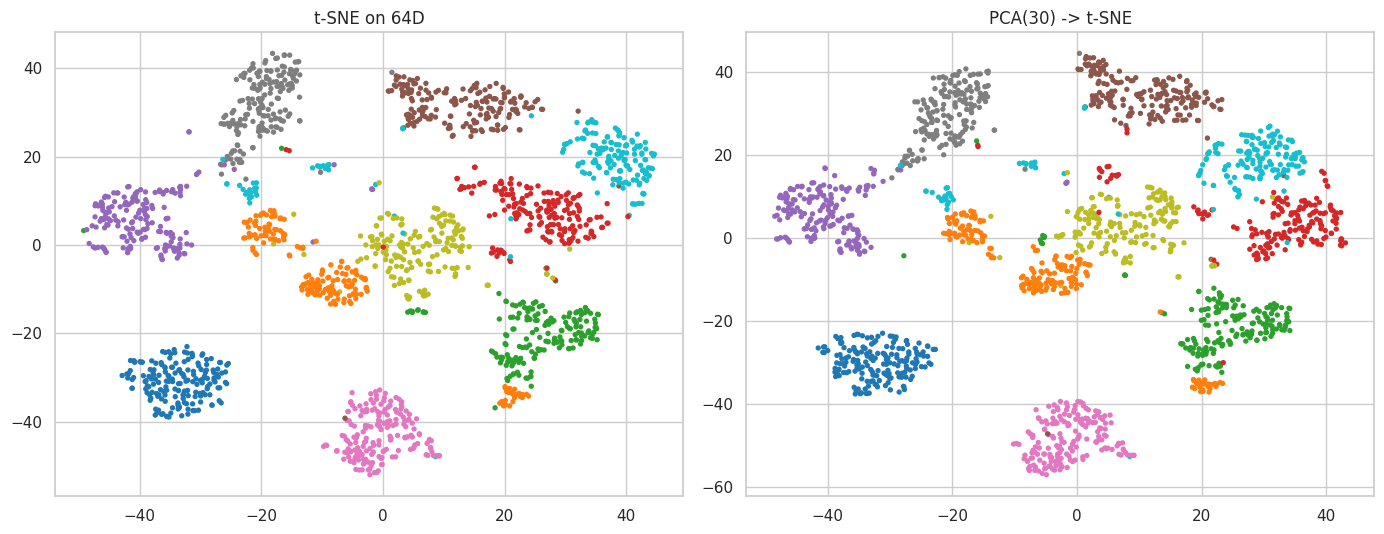

In [6]:
Xs = StandardScaler().fit_transform(X)
t0 = time.time(); Z_direct = TSNE(init="pca", learning_rate="auto", random_state=42).fit_transform(Xs); t_direct = time.time()-t0
X50 = PCA(n_components=30, random_state=42).fit_transform(Xs)
t0 = time.time(); Z_pipe = TSNE(init="pca", learning_rate="auto", random_state=42).fit_transform(X50); t_pipe = time.time()-t0
print(f"Direct: {t_direct:.1f}s | PCA(30)->t-SNE: {t_pipe:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(14,5.5))
for ax, Z, t in zip(axes, [Z_direct, Z_pipe], ["t-SNE on 64D", "PCA(30) -> t-SNE"]):
    ax.scatter(Z[:,0], Z[:,1], c=y, cmap="tab10", s=8); ax.set_title(t)
plt.tight_layout(); plt.show()

## 5. Application: t-SNE on the Wine dataset

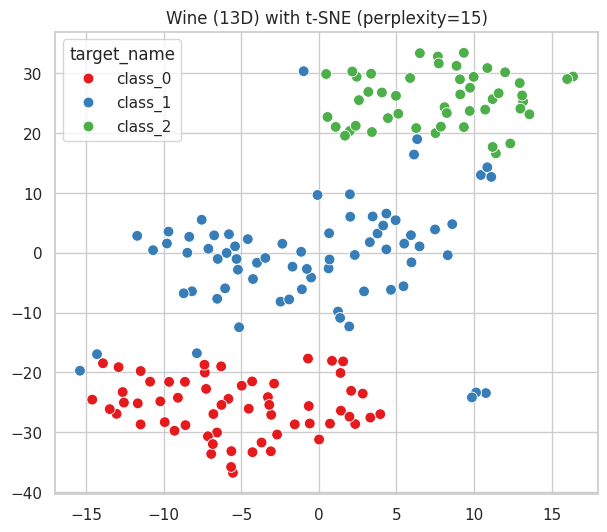

In [7]:
wine = pd.read_csv("../data/wine.csv")
Xw = StandardScaler().fit_transform(wine.drop(columns=["target","target_name"]))
Zw = TSNE(perplexity=15, init="pca", learning_rate="auto", random_state=42).fit_transform(Xw)
plt.figure(figsize=(7,6))
sns.scatterplot(x=Zw[:,0], y=Zw[:,1], hue=wine["target_name"], palette="Set1", s=60)
plt.title("Wine (13D) with t-SNE (perplexity=15)"); plt.show()

## 6. Pitfalls: how NOT to read a t-SNE plot
1. **Cluster sizes mean nothing** - t-SNE equalises density.
2. **Distances between clusters mean little** - only local neighbourhoods are reliable.
3. **Axes have no meaning** - unlike PCA components.
4. **Results depend on perplexity, seed, iterations** - always try several.
5. **Can't transform new data** (no `.transform()` in sklearn) - re-run or use UMAP/parametric t-SNE.
6. **Slow** on big datasets (O(n log n) with Barnes-Hut, still heavy beyond ~100k points).
7. Use it for **visualisation/exploration**, not as input features for models.

## Summary
| Aspect | t-SNE |
|---|---|
| Type | Non-linear, unsupervised |
| Preserves | Local neighbourhood structure |
| Deterministic | No (random init) |
| Speed | Slow |
| Uses | Visualising embeddings, cluster discovery, image/text/genomics data |

## Exercises
1. Try `perplexity` values 5, 20, 50 on Wine. Which one looks best?
2. Try `n_components=3` and plot in 3D.
3. Colour the t-SNE plot by a single pixel feature (e.g. `pixel_3_3`) to see what drives local structure.